# EDA — Project 2 TermA (Aspect & Sentiment Extraction)

Dataset: IndoNLU TermA (AiryRooms Hotel Reviews)
Task: BIO Sequence Labeling untuk `ASPECT` dan `SENTIMENT`

In [1]:
import os
import sys
sys.path.append(os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from src.config import DATA_DIR, LABEL_LIST
from src.data_loader import load_split, validate_dataset

In [2]:
# 1. Muat data train, valid, test
df_train = load_split('train')
df_valid = load_split('valid')
df_test = load_split('test')

print(f"Train sentences: {len(df_train)}")
print(f"Valid sentences: {len(df_valid)}")
print(f"Test sentences: {len(df_test)}")
df_train.head()

Train sentences: 3000
Valid sentences: 1000
Test sentences: 1000


,id,tokens,seq_label,text
0,train_0,"[kamar, saya, ada, kendala, di, ac, tidak, ber...","[O, O, O, O, O, B-ASPECT, B-SENTIMENT, I-SENTI...",kamar saya ada kendala di ac tidak berfungsi o...
1,train_1,"[tempatnya, bagus, ., kolam, renangnya, bersih...","[B-ASPECT, B-SENTIMENT, O, B-ASPECT, I-ASPECT,...",tempatnya bagus . kolam renangnya bersih .
2,train_2,"[oke, banget, ,, tetapi, ac, nya, tidak, bisa,...","[B-SENTIMENT, I-SENTIMENT, O, O, B-ASPECT, I-A...","oke banget , tetapi ac nya tidak bisa diatur s..."
3,train_3,"[pintu, geser, kurang, rapat, .]","[B-ASPECT, I-ASPECT, B-SENTIMENT, I-SENTIMENT, O]",pintu geser kurang rapat .
4,train_4,"[keren, ., nyaman, semuanya, .]","[B-SENTIMENT, O, B-SENTIMENT, B-ASPECT, O]",keren . nyaman semuanya .


In [3]:
# 2. Validasi Anotasi (NLP-T2-03)
for name, df in [('train', df_train), ('valid', df_valid), ('test', df_test)]:
    issues = validate_dataset(df)
    print(f"[{name.upper()}] Illegal transitions: {len(issues['illegal_transitions'])}")

[TRAIN] Illegal transitions: 8
[VALID] Illegal transitions: 0
[TEST] Illegal transitions: 5


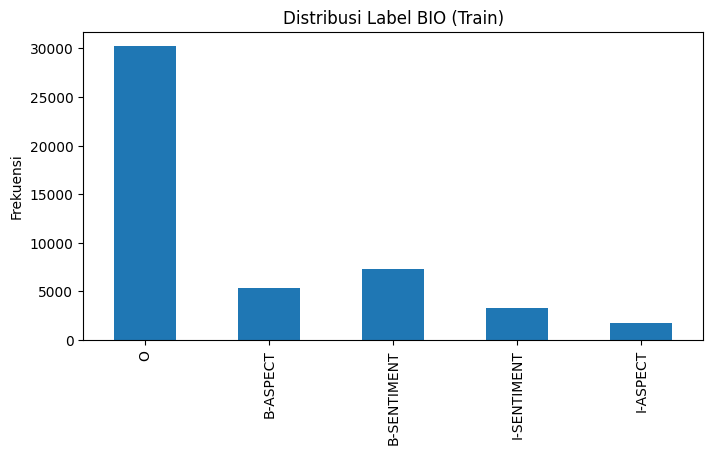

In [4]:
# 3. Distribusi Label BIO (NLP-T3-02)
all_train_labels = [lbl for labels in df_train['seq_label'] for lbl in labels]
label_counts = Counter(all_train_labels)
pd.Series(label_counts).plot(kind='bar', title='Distribusi Label BIO (Train)', figsize=(8, 4))
plt.ylabel('Frekuensi')
plt.show()